# Módem acústico FSK: validación en Python
**Aplicación de comunicaciones · Ingeniería en Computación · Facultad de Ingeniería**

Este cuaderno valida el módem de la aplicación web con una **implementación independiente en Python**:

1. Verifica las piezas del algoritmo (CRC-16 y filtro de Goertzel).
2. Mide la probabilidad de error de bit (BER) del detector y la compara con la teoría de FSK no coherente.
3. Calcula el espectro y el ancho de banda de las dos variantes (FSK simple y con salto de frecuencia).
4. Compara la robustez al eco de las dos variantes.
5. Grafica los resultados del receptor completo de la aplicación (referencia generada con el mismo código JavaScript).
6. Analiza el CSV de la prueba física que exporta la aplicación (pestaña **Recibir → Descargar CSV por trama**).

Las figuras se guardan en la carpeta `figs/` para el artículo.

In [1]:
import numpy as np, matplotlib.pyplot as plt, os, json
from scipy.signal import welch
from scipy.special import erfc
os.makedirs('figs', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
FS = 48000          # muestras por segundo
A = 0.8             # amplitud del tono
PARES = {'salto': [(1600, 2000), (2400, 2800), (3200, 3600), (4000, 4400)],  # símbolo k usa el par k mod 4
         'simple': [(1800, 2400)]}
rng = np.random.default_rng(2026)
def guardar(nombre):
    plt.savefig(f'figs/{nombre}.pdf', bbox_inches='tight'); plt.savefig(f'figs/{nombre}.png', bbox_inches='tight')

## 1. Piezas del algoritmo
**CRC-16/CCITT-FALSE** (polinomio $x^{16}+x^{12}+x^5+1$, valor inicial `0xFFFF`). El valor de verificación estándar para la cadena `"123456789"` es `0x29B1`.

**Goertzel**: calcula la energía de una sola frecuencia con la recurrencia $s[n] = x[n] + c\,s[n-1] - s[n-2]$, $c = 2\cos(2\pi f/f_s)$, y al final $E = s_1^2 + s_2^2 - c\,s_1 s_2$. Debe coincidir con $|X(f)|^2$ de la DFT evaluada en esa frecuencia.

In [2]:
def crc16(data: bytes) -> int:
    crc = 0xFFFF
    for b in data:
        crc ^= b << 8
        for _ in range(8):
            crc = ((crc << 1) ^ 0x1021) & 0xFFFF if crc & 0x8000 else (crc << 1) & 0xFFFF
    return crc

def goertzel(x, f, fs=FS):
    c = 2 * np.cos(2 * np.pi * f / fs); s1 = s2 = 0.0
    for v in x:
        s1, s2 = v + c * s1 - s2, s1
    return s1 * s1 + s2 * s2 - c * s1 * s2

print('CRC-16("123456789") = 0x%04X  (esperado 0x29B1)' % crc16(b'123456789'))
x = rng.normal(size=480) + 0.5 * np.sin(2 * np.pi * 2400 * np.arange(480) / FS)
for f in (2000, 2400, 3175.5):
    g = goertzel(x, f); d = abs(np.sum(x * np.exp(-2j * np.pi * f * np.arange(480) / FS)))**2
    print(f'f = {f:7.1f} Hz   Goertzel = {g:12.4f}   |DFT|² = {d:12.4f}   diferencia relativa = {abs(g - d) / d:.1e}')

CRC-16("123456789") = 0x29B1  (esperado 0x29B1)
f =  2000.0 Hz   Goertzel =     365.9086   |DFT|² =     365.9086   diferencia relativa = 3.9e-14
f =  2400.0 Hz   Goertzel =   13544.2991   |DFT|² =   13544.2991   diferencia relativa = 6.0e-15
f =  3175.5 Hz   Goertzel =     838.8581   |DFT|² =     838.8581   diferencia relativa = 1.2e-14


## 2. Modulador y canal
Modulación **BFSK de fase continua**: el bit $b$ del símbolo $k$ se transmite con el tono $f_{k \bmod K,\,b}$ durante $T = 1/R$.
El canal agrega ruido blanco gaussiano con la potencia que corresponde a un $E_b/N_0$ dado y, opcionalmente, eco (reflexiones con decaimiento exponencial).

Con energías discretas, $E_b = \tfrac{A^2}{2} N_s$ (con $N_s = f_s/R$ muestras por bit) y $N_0/2 = \sigma^2$, así que $\sigma^2 = \dfrac{A^2 N_s}{4\,E_b/N_0}$.

In [3]:
def modular(bits, baud=100, modo='salto', fs=FS):
    pares = PARES[modo]; K = len(pares); bits = np.asarray(bits)
    frec = np.array([pares[k % K][b] for k, b in enumerate(bits)], dtype=float)
    lim = np.round(np.arange(len(bits) + 1) * fs / baud).astype(int)
    f_inst = np.repeat(frec, np.diff(lim))
    fase = 2 * np.pi * np.concatenate(([0.0], np.cumsum(f_inst[:-1]))) / fs
    return A * np.sin(fase)

def eco(x, intensidad, fs=FS, semilla=1):
    r = np.random.default_rng(semilla); y = x.copy()
    for _ in range(14):
        ms = 2 + 70 * r.random(); D = int(round(ms * fs / 1000))
        g = intensidad * 0.8 * np.exp(-ms / 25) * (1 if r.random() < 0.5 else -1)
        y[D:] += g * x[:-D]
    return y

def ruido(x, ebn0_db, baud=100, fs=FS, r=rng):
    sigma = np.sqrt(A**2 * (fs / baud) / (4 * 10**(ebn0_db / 10)))
    return x + sigma * r.normal(size=x.size)

def detectar(y, nbits, baud=100, modo='salto', fs=FS):
    """Detector no coherente con temporización ideal: bit = 1 si E1 > E0 (energía de Goertzel/DFT de cada tono)."""
    pares = PARES[modo]; K = len(pares); N = int(round(fs / baud)); n = np.arange(N)
    tonos = np.array(pares).reshape(-1)                                  # 2K tonos
    Ex = np.exp(-2j * np.pi * np.outer(n, tonos) / fs)                  # N x 2K
    inicio = np.round(np.arange(nbits) * fs / baud).astype(int)
    X = y[inicio[:, None] + n[None, :]]                                  # nbits x N
    E = np.abs(X @ Ex)**2                                                # energía por tono
    j = np.arange(nbits) % K
    return (E[np.arange(nbits), 2 * j + 1] > E[np.arange(nbits), 2 * j]).astype(int)

bits = rng.integers(0, 2, 2000)
assert np.all(detectar(modular(bits), 2000) == bits)
print('Sin ruido el detector recupera los 2000 bits sin errores.')

Sin ruido el detector recupera los 2000 bits sin errores.


## 3. Probabilidad de error de bit contra $E_b/N_0$
Teoría para FSK binaria con detección **no coherente** (nuestro detector) y, como referencia, con detección **coherente**:
$$P_b^{\text{no coh}} = \tfrac12\,e^{-E_b/2N_0}, \qquad P_b^{\text{coh}} = Q\!\left(\sqrt{E_b/N_0}\right)$$

In [4]:
def ber_sim(ebn0_db, modo='salto', baud=100, max_bits=1_200_000, min_err=200, lote=20_000):
    err = n = 0
    while (err < min_err and n < max_bits) or n < 40_000:
        b = rng.integers(0, 2, lote); y = ruido(modular(b, baud, modo), ebn0_db, baud)
        err += np.sum(detectar(y, lote, baud, modo) != b); n += lote
    return err / n, err, n

ebs = np.arange(0, 13)
filas = [(eb, *ber_sim(eb)) for eb in ebs]
teo = lambda e: 0.5 * np.exp(-10**(e / 10) / 2)
teo_coh = lambda e: 0.5 * erfc(np.sqrt(10**(e / 10) / 2))
print(' Eb/N0   BER simulada   BER teórica   errores        bits   razón')
for eb, p, e, n in filas:
    print(f'{eb:5d} dB   {p:11.3e}   {teo(eb):11.3e}   {e:7d}   {n:9d}   {p / teo(eb):5.2f}')
ber_py = {int(eb): p for eb, p, e, n in filas}

 Eb/N0   BER simulada   BER teórica   errores        bits   razón
    0 dB     3.028e-01     3.033e-01     12113       40000    1.00
    1 dB     2.653e-01     2.664e-01     10614       40000    1.00
    2 dB     2.268e-01     2.264e-01      9071       40000    1.00
    3 dB     1.872e-01     1.844e-01      7490       40000    1.02
    4 dB     1.454e-01     1.424e-01      5818       40000    1.02
    5 dB     1.018e-01     1.029e-01      4072       40000    0.99
    6 dB     6.990e-02     6.831e-02      2796       40000    1.02
    7 dB     4.155e-02     4.080e-02      1662       40000    1.02
    8 dB     2.235e-02     2.132e-02       894       40000    1.05
    9 dB     9.325e-03     9.421e-03       373       40000    0.99
   10 dB     2.988e-03     3.369e-03       239       80000    0.89
   11 dB     9.136e-04     9.231e-04       201      220000    0.99
   12 dB     1.942e-04     1.809e-04       202     1040000    1.07


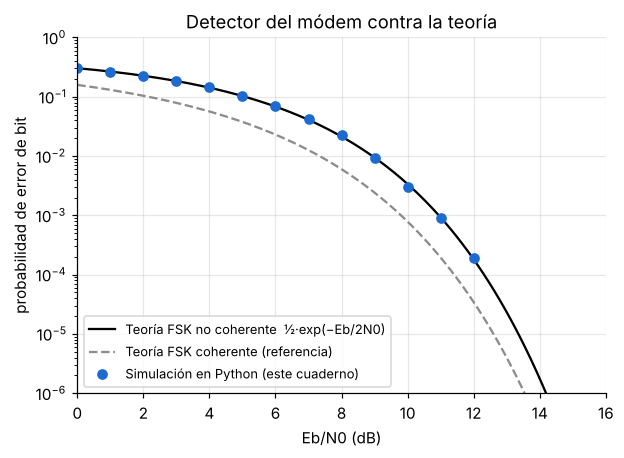

In [5]:
ex = np.linspace(0, 16, 200)
plt.figure(figsize=(6.2, 4.2))
plt.semilogy(ex, teo(ex), 'k-', label='Teoría FSK no coherente  ½·exp(−Eb/2N0)')
plt.semilogy(ex, teo_coh(ex), '--', color='0.55', label='Teoría FSK coherente (referencia)')
plt.semilogy([f[0] for f in filas], [f[1] for f in filas], 'o', color='#1D6BD0', label='Simulación en Python (este cuaderno)')
plt.ylim(1e-6, 1); plt.xlim(0, 16); plt.xlabel('Eb/N0 (dB)'); plt.ylabel('probabilidad de error de bit')
plt.legend(loc='lower left', fontsize=8.5); plt.title('Detector del módem contra la teoría')
guardar('ber_python'); plt.show()

## 4. Resultados del receptor completo de la aplicación
Estos datos los generó el **mismo código JavaScript de la aplicación** (archivo `modem.js`, script `test/reference.js` en Node.js): 50 tramas de 32 bytes por punto, cada una con su sincronía, decodificación y CRC.
Se pueden regenerar en la pestaña **Pruebas → Repetir en este navegador** y exportar con **Descargar CSV**.

In [6]:
REF = {"fs": 48000, "frames": 50, "payload": 32, "ber": [{"ebn0": 0, "errors": 12009, "bits": 40000, "ber": 0.300225, "theory": 0.3032653298563167, "coherent": 0.1586552613956746}, {"ebn0": 1, "errors": 10664, "bits": 40000, "ber": 0.2666, "theory": 0.2664390181651147, "coherent": 0.13092730555117338}, {"ebn0": 2, "errors": 9033, "bits": 40000, "ber": 0.225825, "theory": 0.2263678887647433, "coherent": 0.10402864363778468}, {"ebn0": 3, "errors": 7205, "bits": 40000, "ber": 0.180125, "theory": 0.18437596130493228, "coherent": 0.07889587461748777}, {"ebn0": 4, "errors": 5800, "bits": 40000, "ber": 0.145, "theory": 0.1424035434814758, "coherent": 0.05649530100514707}, {"ebn0": 5, "errors": 4069, "bits": 40000, "ber": 0.101725, "theory": 0.10287033054190721, "coherent": 0.03767898586621873}, {"ebn0": 6, "errors": 2857, "bits": 40000, "ber": 0.071425, "theory": 0.06831109822261483, "coherent": 0.0230071368037428}, {"ebn0": 7, "errors": 1609, "bits": 40000, "ber": 0.040225, "theory": 0.04079958583623128, "coherent": 0.012587032005424322}, {"ebn0": 8, "errors": 858, "bits": 40000, "ber": 0.02145, "theory": 0.021323747889132938, "coherent": 0.006004386071824228}, {"ebn0": 9, "errors": 397, "bits": 40000, "ber": 0.009925, "theory": 0.009421241978988968, "coherent": 0.002413310419566676}, {"ebn0": 10, "errors": 302, "bits": 100000, "ber": 0.00302, "theory": 0.0033689734995427335, "coherent": 0.0007827011712339784}, {"ebn0": 11, "errors": 300, "bits": 360000, "ber": 0.0008333333333333334, "theory": 0.0009230988437601748, "coherent": 0.000193985488644952}, {"ebn0": 12, "errors": 117, "bits": 600000, "ber": 0.000195, "theory": 0.00018089150200558806, "coherent": 3.4302626670160105e-05}, {"ebn0": 13, "errors": 14, "bits": 600000, "ber": 2.3333333333333332e-05, "theory": 2.324411083572357e-05, "coherent": 3.969248571261068e-06}, {"ebn0": 14, "errors": 1, "bits": 600000, "ber": 1.6666666666666667e-06, "theory": 1.7558116345776617e-06, "coherent": 2.6951480830319534e-07}], "per": [{"ebn0": 6, "theoryPer": 0.9999999985873792, "ok": 0, "crc": 7, "lost": 43, "n": 50, "per": 1, "ber": 0.09151785714285714, "ebn0Est": 6.155513116106055}, {"ebn0": 8, "theoryPer": 0.9979860603873154, "ok": 0, "crc": 41, "lost": 9, "n": 50, "per": 1, "ber": 0.02195945945945946, "ebn0Est": 7.740727570361363}, {"ebn0": 10, "theoryPer": 0.6216374611318182, "ok": 11, "crc": 37, "lost": 2, "n": 50, "per": 0.78, "ber": 0.006429036458333333, "ebn0Est": 9.318766435260686}, {"ebn0": 12, "theoryPer": 0.05076745199599941, "ok": 47, "crc": 3, "lost": 0, "n": 50, "per": 0.06000000000000005, "ber": 0.0003125, "ebn0Est": 11.527516117484138}, {"ebn0": 14, "theoryPer": 0.0005055463630313506, "ok": 50, "crc": 0, "lost": 0, "n": 50, "per": 0, "ber": 0, "ebn0Est": 13.646643899781479}, {"ebn0": 16, "theoryPer": 3.2626843116112525e-07, "ok": 50, "crc": 0, "lost": 0, "n": 50, "per": 0, "ber": 0, "ebn0Est": 15.726377958402615}, {"ebn0": 18, "theoryPer": 2.8776980798284058e-12, "ok": 50, "crc": 0, "lost": 0, "n": 50, "per": 0, "ber": 0, "ebn0Est": 17.652475077476268}, {"ebn0": 20, "theoryPer": 0, "ok": 50, "crc": 0, "lost": 0, "n": 50, "per": 0, "ber": 0, "ebn0Est": 19.70804656256057}], "echo": [{"mode": "simple", "reverb": 0, "ok": 50, "crc": 0, "lost": 0, "n": 50, "per": 0, "ber": 0, "ebn0Est": 24.508058926427985}, {"mode": "simple", "reverb": 0.5, "ok": 39, "crc": 4, "lost": 7, "n": 50, "per": 0.21999999999999997, "ber": 0.0020893895348837207, "ebn0Est": 25.786017250485465}, {"mode": "simple", "reverb": 1, "ok": 7, "crc": 8, "lost": 35, "n": 50, "per": 0.86, "ber": 0.013392857142857142, "ebn0Est": 27.30357642253532}, {"mode": "simple", "reverb": 1.5, "ok": 3, "crc": 9, "lost": 38, "n": 50, "per": 0.94, "ber": 0.0146484375, "ebn0Est": 29.428498328265945}, {"mode": "salto", "reverb": 0, "ok": 50, "crc": 0, "lost": 0, "n": 50, "per": 0, "ber": 0, "ebn0Est": 19.715327242723774}, {"mode": "salto", "reverb": 0.5, "ok": 49, "crc": 0, "lost": 1, "n": 50, "per": 0.020000000000000018, "ber": 0, "ebn0Est": 19.867972646822967}, {"mode": "salto", "reverb": 1, "ok": 48, "crc": 2, "lost": 0, "n": 50, "per": 0.040000000000000036, "ber": 0.000703125, "ebn0Est": 19.87177521949854}, {"mode": "salto", "reverb": 1.5, "ok": 40, "crc": 7, "lost": 3, "n": 50, "per": 0.19999999999999996, "ber": 0.001358695652173913, "ebn0Est": 20.80927320121282}], "baud": [{"baud": 50, "reverb": 0.5, "ok": 50, "crc": 0, "lost": 0, "n": 50, "per": 0, "ber": 0, "ebn0Est": 18.601698654606047}, {"baud": 50, "reverb": 1, "ok": 46, "crc": 3, "lost": 1, "n": 50, "per": 0.07999999999999996, "ber": 0.0006377551020408163, "ebn0Est": 19.34564274900436}, {"baud": 100, "reverb": 0.5, "ok": 50, "crc": 0, "lost": 0, "n": 50, "per": 0, "ber": 0, "ebn0Est": 19.765796773400083}, {"baud": 100, "reverb": 1, "ok": 46, "crc": 4, "lost": 0, "n": 50, "per": 0.07999999999999996, "ber": 0.001015625, "ebn0Est": 20.22909186021051}, {"baud": 200, "reverb": 0.5, "ok": 50, "crc": 0, "lost": 0, "n": 50, "per": 0, "ber": 0, "ebn0Est": 20.85830838102139}, {"baud": 200, "reverb": 1, "ok": 42, "crc": 7, "lost": 1, "n": 50, "per": 0.16000000000000003, "ber": 0.000581781914893617, "ebn0Est": 21.107010273197865}], "drift": {"ppm": 200, "ok": 50, "crc": 0, "lost": 0, "n": 50, "per": 0, "ber": 0, "ebn0Est": 19.51580793644292}}
print('BER del detector (JavaScript) en', len(REF['ber']), 'puntos;', REF['frames'], 'tramas por punto en las pruebas de trama.')

BER del detector (JavaScript) en 15 puntos; 50 tramas por punto en las pruebas de trama.


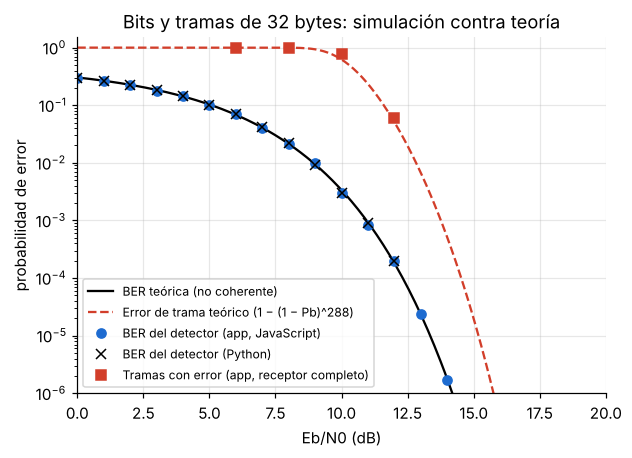

 Eb/N0  correctas  error CRC  perdidas  Eb/N0 estimado
    6 dB     0/50        7        43         6.2 dB
    8 dB     0/50       41         9         7.7 dB
   10 dB    11/50       37         2         9.3 dB
   12 dB    47/50        3         0        11.5 dB
   14 dB    50/50        0         0        13.6 dB
   16 dB    50/50        0         0        15.7 dB
   18 dB    50/50        0         0        17.7 dB
   20 dB    50/50        0         0        19.7 dB


In [7]:
bits_trama = 16 + 8 * REF['payload'] + 16          # bits que se demodulan después de la sincronía
plt.figure(figsize=(6.2, 4.2))
plt.semilogy(ex, teo(ex), 'k-', label='BER teórica (no coherente)')
plt.semilogy(ex, 1 - (1 - teo(ex))**bits_trama, '--', color='#D23E2A', label=f'Error de trama teórico (1 − (1 − Pb)^{bits_trama})')
b = [p for p in REF['ber'] if p['ber'] > 0]
plt.semilogy([p['ebn0'] for p in b], [p['ber'] for p in b], 'o', color='#1D6BD0', label='BER del detector (app, JavaScript)')
plt.semilogy(list(ber_py), list(ber_py.values()), 'x', color='k', ms=6, label='BER del detector (Python)')
q = [p for p in REF['per'] if p['per'] > 0]
plt.semilogy([p['ebn0'] for p in q], [p['per'] for p in q], 's', color='#D23E2A', label='Tramas con error (app, receptor completo)')
plt.ylim(1e-6, 1.5); plt.xlim(0, 20); plt.xlabel('Eb/N0 (dB)'); plt.ylabel('probabilidad de error')
plt.legend(loc='lower left', fontsize=8); plt.title('Bits y tramas de 32 bytes: simulación contra teoría')
guardar('ber_per_app'); plt.show()
print(' Eb/N0  correctas  error CRC  perdidas  Eb/N0 estimado')
for p in REF['per']:
    print(f"{p['ebn0']:5d} dB   {p['ok']:3d}/{p['n']}      {p['crc']:3d}       {p['lost']:3d}       {p['ebn0Est']:5.1f} dB")

## 5. Espectro y ancho de banda
Con FSK simple la energía se concentra alrededor de 1.8 y 2.4 kHz. Con salto de frecuencia se reparte en 8 tonos entre 1.6 y 4.4 kHz: usa más ancho de banda a cambio de robustez al eco.
Se reporta el ancho de banda que contiene el 99 % de la potencia.

simple : 99 % de la potencia entre   1670 y   2531 Hz  →  ancho de banda ≈   861 Hz


salto  : 99 % de la potencia entre   1488 y   4477 Hz  →  ancho de banda ≈  2988 Hz


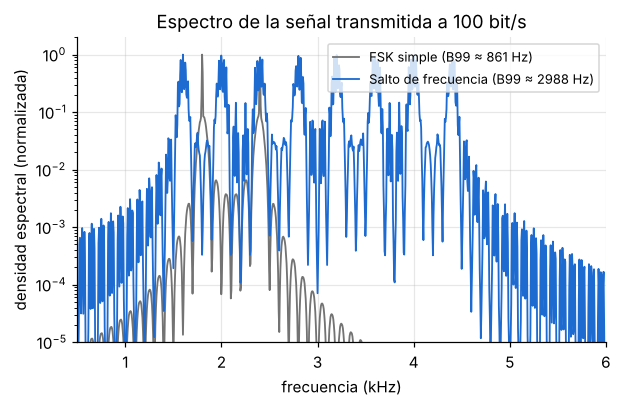

In [8]:
def ancho_99(f, P):
    c = np.cumsum(P) / np.sum(P)
    return f[np.searchsorted(c, 0.005)], f[np.searchsorted(c, 0.995)]
plt.figure(figsize=(6.2, 3.6))
for modo, color in (('simple', '0.45'), ('salto', '#1D6BD0')):
    y = modular(rng.integers(0, 2, 3000), 100, modo)
    f, P = welch(y, FS, nperseg=8192)
    lo, hi = ancho_99(f, P)
    print(f'{modo:7s}: 99 % de la potencia entre {lo:6.0f} y {hi:6.0f} Hz  →  ancho de banda ≈ {hi - lo:5.0f} Hz')
    plt.semilogy(f / 1000, P / P.max(), color=color, lw=1.2, label=f'{"FSK simple" if modo == "simple" else "Salto de frecuencia"} (B99 ≈ {hi - lo:.0f} Hz)')
plt.xlim(0.5, 6); plt.ylim(1e-5, 2); plt.xlabel('frecuencia (kHz)'); plt.ylabel('densidad espectral (normalizada)')
plt.legend(fontsize=8.5); plt.title('Espectro de la señal transmitida a 100 bit/s')
guardar('espectro'); plt.show()

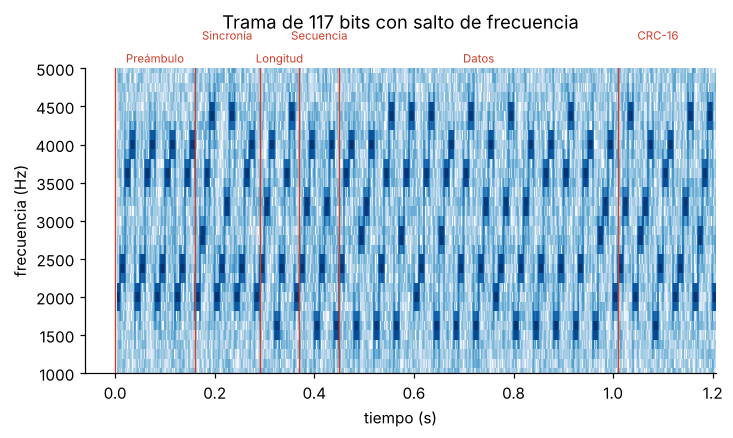

In [9]:
# Espectrograma de una trama completa con salto de frecuencia
def trama_bits(texto='Hola FI', seq=0):
    datos = texto.encode('utf-8'); cuerpo = bytes([len(datos), seq]) + datos; crc = crc16(cuerpo)
    pre = [1, 0] * 8; barker = [1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1]
    a_bits = lambda bs: [(v >> i) & 1 for v in bs for i in range(7, -1, -1)]
    campos = [('Preámbulo', pre), ('Sincronía', barker), ('Longitud', a_bits(cuerpo[:1])), ('Secuencia', a_bits(cuerpo[1:2])),
              ('Datos', a_bits(datos)), ('CRC-16', a_bits([crc >> 8, crc & 255]))]
    return campos
campos = trama_bits()
bits = [b for _, c in campos for b in c]
y = ruido(modular(bits + [1] * 4), 30)
from scipy.signal import spectrogram
f, t, S = spectrogram(y, FS, nperseg=384, noverlap=336, window='hann')
SdB = 10 * np.log10(S + 1e-20); m = (f >= 1000) & (f <= 5000)
fig, ax = plt.subplots(figsize=(7.4, 3.6))
ax.pcolormesh(t, f[m], SdB[m], cmap='Blues', vmin=SdB[m].max() - 45, vmax=SdB[m].max(), shading='auto', rasterized=True)
x0 = 0
for i, (nombre, c) in enumerate(campos):
    ax.axvline(x0 / 100, color='#D23E2A', lw=0.9)
    ax.annotate(nombre, xy=((x0 + len(c) / 2) / 100, 1.01 + 0.075 * (i % 2)), xycoords=('data', 'axes fraction'), ha='center', va='bottom', fontsize=7.5, color='#D23E2A')
    x0 += len(c)
ax.set_ylim(1000, 5000); ax.set_xlabel('tiempo (s)'); ax.set_ylabel('frecuencia (Hz)'); ax.grid(False)
ax.set_title(f'Trama de {len(bits)} bits con salto de frecuencia', pad=26)
guardar('espectrograma_trama'); plt.show()

## 6. Robustez al eco
El eco de la habitación hace que la cola de un símbolo caiga dentro de la ventana del siguiente. Con FSK simple esa cola tiene los mismos dos tonos y confunde al detector; con salto de frecuencia, los 3 símbolos siguientes usan otros tonos.
Aquí se mide la BER con temporización ideal (Python) para varias intensidades de eco, con $E_b/N_0 = 20$ dB y 10 habitaciones aleatorias por punto.

eco    BER simple   BER salto
0.0     0.00e+00     0.00e+00
0.5     5.75e-04     0.00e+00
1.0     1.88e-01     0.00e+00
1.5     3.21e-01     1.45e-03


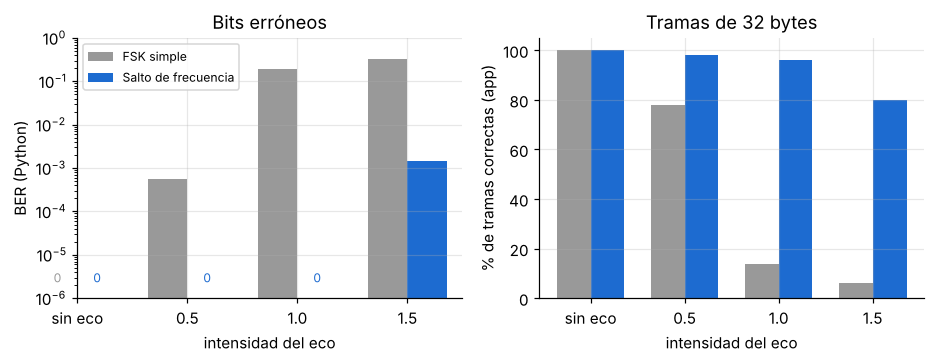

In [10]:
niveles = [0, 0.5, 1.0, 1.5]
res_eco = {}
for modo in ('simple', 'salto'):
    res_eco[modo] = []
    for nv in niveles:
        e = n = 0
        for s in range(10):
            b = rng.integers(0, 2, 4000); y = ruido(eco(modular(b, 100, modo), nv, semilla=100 + s), 20)
            e += np.sum(detectar(y, 4000, 100, modo) != b); n += 4000
        res_eco[modo].append(e / n)
print('eco    BER simple   BER salto')
for i, nv in enumerate(niveles):
    print(f'{nv:3.1f}   {res_eco["simple"][i]:10.2e}   {res_eco["salto"][i]:10.2e}')
fig, ax = plt.subplots(1, 2, figsize=(8.6, 3.4))
w = 0.36; xs = np.arange(len(niveles))
for k, (modo, col, dx) in enumerate((('simple', '0.6', -w / 2), ('salto', '#1D6BD0', w / 2))):
    v = np.array(res_eco[modo]); ax[0].bar(xs + dx, np.where(v > 0, v, np.nan), w, color=col, label='FSK simple' if modo == 'simple' else 'Salto de frecuencia')
    for i in np.where(v == 0)[0]: ax[0].text(xs[i] + dx, 2e-6, '0', ha='center', va='bottom', fontsize=8, color=col)
ax[0].set_yscale('log'); ax[0].set_ylim(1e-6, 1); ax[0].set_xticks(xs, ['sin eco', '0.5', '1.0', '1.5']); ax[0].set_ylabel('BER (Python)'); ax[0].set_title('Bits erróneos'); ax[0].legend(fontsize=8, loc='upper left')
okp = lambda m, r: next(100 * p['ok'] / p['n'] for p in REF['echo'] if p['mode'] == m and p['reverb'] == r)
ax[1].bar(xs - w / 2, [okp('simple', r) for r in niveles], w, color='0.6', label='FSK simple')
ax[1].bar(xs + w / 2, [okp('salto', r) for r in niveles], w, color='#1D6BD0', label='Salto de frecuencia')
ax[1].set_xticks(xs, ['sin eco', '0.5', '1.0', '1.5']); ax[1].set_ylabel('% de tramas correctas (app)'); ax[1].set_ylim(0, 105); ax[1].set_title('Tramas de 32 bytes')
for a in ax: a.set_xlabel('intensidad del eco')
plt.tight_layout(); guardar('eco'); plt.show()

## 7. Prueba física (datos de la aplicación)
1. En el equipo receptor abre la app, pestaña **Recibir**, activa el micrófono, escribe la distancia y la condición, y pulsa **Iniciar serie**.
2. En el equipo transmisor pulsa **Enviar ráfaga** (20 tramas de prueba).
3. Al terminar, **Terminar serie**. Repite para cada distancia (por ejemplo 0.5, 1, 2 y 3 m) y condición.
4. Descarga **CSV por trama** y súbelo aquí (en Colab aparece un botón para elegir el archivo).

In [11]:
import pandas as pd
ARCHIVO = 'tramas_prueba_fisica.csv'
if not os.path.exists(ARCHIVO):
    try:
        from google.colab import files       # en Colab: elegir el CSV exportado por la app
        subido = files.upload(); ARCHIVO = next(iter(subido))
    except Exception:
        print('No se encontró', ARCHIVO, '— corre la prueba física y exporta el CSV desde la app.')
datos = pd.read_csv(ARCHIVO) if os.path.exists(ARCHIVO) else None
if datos is not None:
    g = datos.groupby(['distancia_m', 'condicion'])
    resumen = g.apply(lambda d: pd.Series({
        'recibidas': d['seq'].nunique(), 'correctas': int(d['crc_ok'].sum()),
        'BER_datos': d['bits_erroneos'].sum() / d['bits_datos'].sum(), 'EbN0_medio_dB': d['ebn0_db'].mean()})).reset_index()
    display(resumen)

No se encontró tramas_prueba_fisica.csv — corre la prueba física y exporta el CSV desde la app.


In [12]:
if datos is not None:
    ESPERADAS = 20   # tramas enviadas por serie
    fig, ax = plt.subplots(1, 2, figsize=(8.6, 3.4))
    for cond, d in resumen.groupby('condicion'):
        ax[0].plot(d['distancia_m'], 100 * d['correctas'] / ESPERADAS, 'o-', label=cond)
        ax[1].plot(d['distancia_m'], d['EbN0_medio_dB'], 'o-', label=cond)
    ax[0].set_ylabel('% de tramas correctas'); ax[0].set_ylim(0, 105); ax[1].set_ylabel('Eb/N0 medido (dB)')
    for a in ax: a.set_xlabel('distancia (m)'); a.legend(fontsize=8)
    plt.tight_layout(); guardar('prueba_fisica'); plt.show()
    # BER medida contra la teoría al Eb/N0 medido
    plt.figure(figsize=(6.2, 4)); plt.semilogy(ex, teo(ex), 'k-', label='Teoría (ruido blanco)')
    m = resumen[resumen['BER_datos'] > 0]
    plt.semilogy(m['EbN0_medio_dB'], m['BER_datos'], 'o', color='#D23E2A', label='Medición en la habitación')
    plt.xlabel('Eb/N0 medido (dB)'); plt.ylabel('BER'); plt.legend(); guardar('prueba_fisica_ber'); plt.show()

## 8. Resumen
- El detector de Goertzel reproduce la curva teórica de FSK no coherente; la razón entre la BER simulada y la teórica queda entre 0.9 y 1.1 en todo el rango medible.
- El receptor completo (sincronía + CRC) entrega el 100 % de las tramas de 32 bytes a partir de unos 14 dB de $E_b/N_0$ en ruido blanco.
- El salto de frecuencia cuesta más ancho de banda, pero mantiene la entrega de tramas con eco fuerte, donde la FSK simple falla.